In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!ls "/content/drive/MyDrive/Processed_Binned"

monkeyN_day1_IT_binned.npz  monkeyN_day3_IT_binned.npz
monkeyN_day1_V1_binned.npz  monkeyN_day3_V1_binned.npz
monkeyN_day1_V4_binned.npz  monkeyN_day3_V4_binned.npz
monkeyN_day2_IT_binned.npz  monkeyN_day4_IT_binned.npz
monkeyN_day2_V1_binned.npz  monkeyN_day4_V1_binned.npz
monkeyN_day2_V4_binned.npz  monkeyN_day4_V4_binned.npz


binned_mua: (20, 9176, 256) float32
train_idx: (9176,) int64


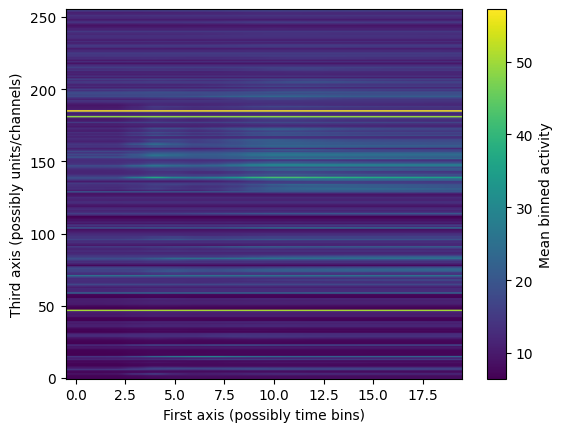

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

path = "/content/drive/MyDrive/Processed_Binned/monkeyN_day1_IT_binned.npz"

with np.load(path) as data:
    mua = data["binned_mua"]
    train_idx = data["train_idx"]

print("binned_mua:", mua.shape, mua.dtype)
print("train_idx:", train_idx.shape, train_idx.dtype)

mean_activity = mua.mean(axis=1)  # shape: (20, 256)

plt.imshow(mean_activity.T, aspect="auto", origin="lower")
plt.xlabel("First axis (possibly time bins)")
plt.ylabel("Third axis (possibly units/channels)")
plt.colorbar(label="Mean binned activity")
plt.show()

V1 shape: (20, 9176, 512)
V4 shape: (20, 9176, 256)
IT shape: (20, 9176, 256)
V1 and V4 have the same train_idx: True
V1 and IT have the same train_idx: True


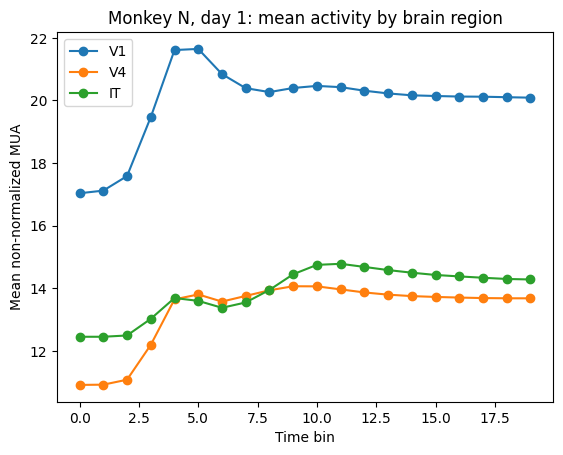

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

folder = Path("/content/drive/MyDrive/Processed_Binned")
regions = ["V1", "V4", "IT"]
curves = {}
indices = {}

for region in regions:
    path = folder / f"monkeyN_day1_{region}_binned.npz"

    with np.load(path) as data:
        mua = data["binned_mua"]
        indices[region] = data["train_idx"]

    print(region, "shape:", mua.shape)
    # Average over presentations and channels, leaving one mean per time bin.
    curves[region] = mua.mean(axis=(1, 2))

for region in regions[1:]:
    print(
        f"V1 and {region} have the same train_idx:",
        np.array_equal(indices["V1"], indices[region])
    )

for region in regions:
    plt.plot(curves[region], marker="o", label=region)

plt.xlabel("Time bin")
plt.ylabel("Mean non-normalized MUA")
plt.title("Monkey N, day 1: mean activity by brain region")
plt.legend()
plt.show()

Day 1, V1: shape (20, 9176, 512)
Day 1, V4: shape (20, 9176, 256)
Day 1, IT: shape (20, 9176, 256)
Day 1: train_idx matches across regions: True
Day 2, V1: shape (20, 5855, 512)
Day 2, V4: shape (20, 5855, 256)
Day 2, IT: shape (20, 5855, 256)
Day 2: train_idx matches across regions: True
Day 3, V1: shape (20, 4602, 512)
Day 3, V4: shape (20, 4602, 256)
Day 3, IT: shape (20, 4602, 256)
Day 3: train_idx matches across regions: True
Day 4, V1: shape (20, 2615, 512)
Day 4, V4: shape (20, 2615, 256)
Day 4, IT: shape (20, 2615, 256)
Day 4: train_idx matches across regions: True


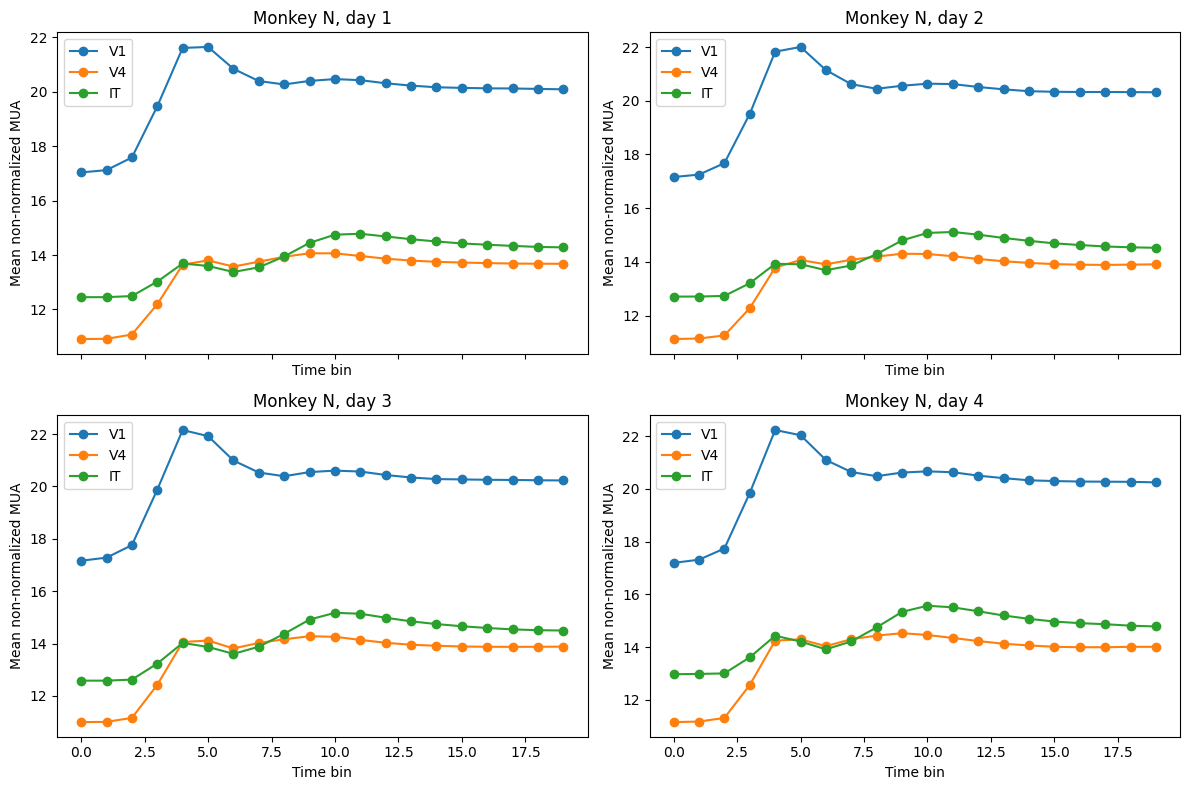

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

folder = Path("/content/drive/MyDrive/Processed_Binned")
regions = ["V1", "V4", "IT"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)

for day, ax in enumerate(axes.flat, start=1):
    indices = {}

    for region in regions:
        path = folder / f"monkeyN_day{day}_{region}_binned.npz"

        with np.load(path) as data:
            mua = data["binned_mua"]
            indices[region] = data["train_idx"].copy()

        print(f"Day {day}, {region}: shape {mua.shape}")

        # Average over presentations and channels; keep the time-bin axis.
        mean_by_time = mua.mean(axis=(1, 2))
        ax.plot(mean_by_time, marker="o", label=region)

    # Check whether the three regions use the same presentation indices.
    same_indices = (
        np.array_equal(indices["V1"], indices["V4"])
        and np.array_equal(indices["V1"], indices["IT"])
    )
    print(f"Day {day}: train_idx matches across regions: {same_indices}")

    ax.set_title(f"Monkey N, day {day}")
    ax.set_xlabel("Time bin")
    ax.set_ylabel("Mean non-normalized MUA")
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
for day in range(1, 5):
    for region in ["V1", "V4", "IT"]:
        path = folder / f"monkeyN_day{day}_{region}_binned.npz"

        with np.load(path) as data:
            mua = data["binned_mua"]
            train_idx = data["train_idx"]
            print(
                f"day {day}, {region}: "
                f"binned_mua={mua.shape}, train_idx={train_idx.shape}"
            )

day 1, V1: binned_mua=(20, 9176, 512), train_idx=(9176,)
day 1, V4: binned_mua=(20, 9176, 256), train_idx=(9176,)
day 1, IT: binned_mua=(20, 9176, 256), train_idx=(9176,)
day 2, V1: binned_mua=(20, 5855, 512), train_idx=(5855,)
day 2, V4: binned_mua=(20, 5855, 256), train_idx=(5855,)
day 2, IT: binned_mua=(20, 5855, 256), train_idx=(5855,)
day 3, V1: binned_mua=(20, 4602, 512), train_idx=(4602,)
day 3, V4: binned_mua=(20, 4602, 256), train_idx=(4602,)
day 3, IT: binned_mua=(20, 4602, 256), train_idx=(4602,)
day 4, V1: binned_mua=(20, 2615, 512), train_idx=(2615,)
day 4, V4: binned_mua=(20, 2615, 256), train_idx=(2615,)
day 4, IT: binned_mua=(20, 2615, 256), train_idx=(2615,)


Day 1, V1: shape = (20, 9176, 512)
Day 1, V4: shape = (20, 9176, 256)
Day 1, IT: shape = (20, 9176, 256)
Day 2, V1: shape = (20, 5855, 512)
Day 2, V4: shape = (20, 5855, 256)
Day 2, IT: shape = (20, 5855, 256)
Day 3, V1: shape = (20, 4602, 512)
Day 3, V4: shape = (20, 4602, 256)
Day 3, IT: shape = (20, 4602, 256)
Day 4, V1: shape = (20, 2615, 512)
Day 4, V4: shape = (20, 2615, 256)
Day 4, IT: shape = (20, 2615, 256)


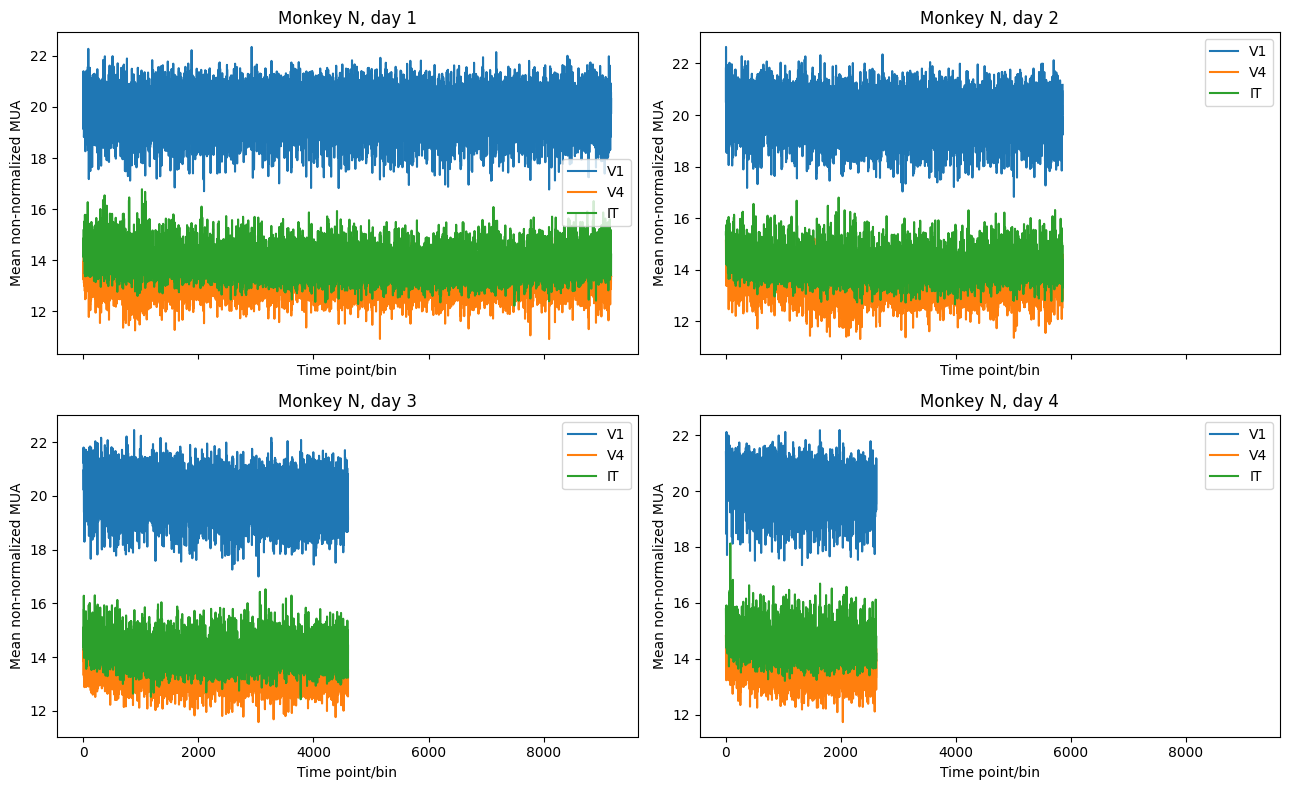

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

folder = Path("/content/drive/MyDrive/Processed_Binned")
regions = ["V1", "V4", "IT"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)

for day, ax in enumerate(axes.flat, start=1):
    for region in regions:
        path = folder / f"monkeyN_day{day}_{region}_binned.npz"

        with np.load(path) as data:
            mua = data["binned_mua"]

        print(f"Day {day}, {region}: shape = {mua.shape}")

        # Shape is trials × time × electrodes.
        mean_by_time = mua.mean(axis=(0, 2))
        ax.plot(mean_by_time, label=region)

    ax.set_title(f"Monkey N, day {day}")
    ax.set_xlabel("Time point/bin")
    ax.set_ylabel("Mean non-normalized MUA")
    ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from pathlib import Path

path = folder / "monkeyN_day1_IT_binned.npz"

with np.load(path) as data:
    idx = np.asarray(data["train_idx"]).squeeze()

print("shape:", idx.shape, "dtype:", idx.dtype)
print("first values:", idx[:30])
print("min/max:", idx.min(), idx.max())
print("unique values:", len(np.unique(idx)))

# Look for likely metadata or recording-log files beside Processed_Binned.
for p in folder.parent.rglob("*"):
    if p.is_file() and p.suffix.lower() in {".mat", ".csv", ".tsv", ".json", ".txt"}:
        print(p)

shape: (9176,) dtype: int64
first values: [16504 16470 15094  2514  4860  7629 16848 14786  6286  6200 14774 12694
 19756 21065 20147 11540  4363  3916  5665  3182 15558 10984 15820 18891
 16544  1348 21225  1272  1452 20003]
min/max: 4 22247
unique values: 9176
/content/drive/MyDrive/all_sales_cleanedv2.csv
/content/drive/MyDrive/file3.csv
/content/drive/MyDrive/
 (6).txt
/content/drive/MyDrive/
 (5).txt
/content/drive/MyDrive/
 (4).txt
/content/drive/MyDrive/
 (3).txt
/content/drive/MyDrive/
 (2).txt
/content/drive/MyDrive/
 (1).txt
/content/drive/MyDrive/
.txt
/content/drive/MyDrive/Fundamentals of Machine Learning/Colab Notebooks/HW #1 FML/housingUnits (1).csv


In [ ]:
from pathlib import Path
import numpy as np

folder = Path("/content/drive/MyDrive/Processed_Binned")

reference = None

for path in sorted(folder.glob("*.npz")):
    with np.load(path) as data:
        idx = data["train_idx"].ravel()

    same_as_first = reference is not None and np.array_equal(idx, reference)
    if reference is None:
        reference = idx.copy()

    print(
        path.name,
        "| indices:", len(idx),
        "| range:", (idx.min(), idx.max()),
        "| same as first file:", same_as_first
    )

monkeyN_day1_IT_binned.npz | indices: 9176 | range: (np.int64(4), np.int64(22247)) | same as first file: False
monkeyN_day1_V1_binned.npz | indices: 9176 | range: (np.int64(4), np.int64(22247)) | same as first file: True
monkeyN_day1_V4_binned.npz | indices: 9176 | range: (np.int64(4), np.int64(22247)) | same as first file: True
monkeyN_day2_IT_binned.npz | indices: 5855 | range: (np.int64(13), np.int64(22244)) | same as first file: False
monkeyN_day2_V1_binned.npz | indices: 5855 | range: (np.int64(13), np.int64(22244)) | same as first file: False
monkeyN_day2_V4_binned.npz | indices: 5855 | range: (np.int64(13), np.int64(22244)) | same as first file: False
monkeyN_day3_IT_binned.npz | indices: 4602 | range: (np.int64(10), np.int64(22248)) | same as first file: False
monkeyN_day3_V1_binned.npz | indices: 4602 | range: (np.int64(10), np.int64(22248)) | same as first file: False
monkeyN_day3_V4_binned.npz | indices: 4602 | range: (np.int64(10), np.int64(22248)) | same as first file: Fal

In [ ]:
import numpy as np
from pathlib import Path

folder = Path("/content/drive/MyDrive/Processed_Binned")
indices_by_day = {}

for day in range(1, 5):
    path = folder / f"monkeyN_day{day}_IT_binned.npz"
    with np.load(path) as data:
        indices_by_day[day] = data["train_idx"].ravel()

all_indices = np.concatenate(list(indices_by_day.values()))

print("Total entries:", len(all_indices))
print("Unique entries:", len(np.unique(all_indices)))
print("Range:", all_indices.min(), "to", all_indices.max())
print("Exactly 1-based IDs 1–22248:",
      np.array_equal(np.sort(all_indices), np.arange(1, 22249)))
print("Exactly 0-based IDs 0–22247:",
      np.array_equal(np.sort(all_indices), np.arange(0, 22248)))

for day_a in range(1, 5):
    for day_b in range(day_a + 1, 5):
        overlap = np.intersect1d(indices_by_day[day_a], indices_by_day[day_b])
        print(f"Days {day_a} and {day_b} shared IDs:", len(overlap))

Total entries: 22248
Unique entries: 22248
Range: 1 to 22248
Exactly 1-based IDs 1–22248: True
Exactly 0-based IDs 0–22247: False
Days 1 and 2 shared IDs: 0
Days 1 and 3 shared IDs: 0
Days 1 and 4 shared IDs: 0
Days 2 and 3 shared IDs: 0
Days 2 and 4 shared IDs: 0
Days 3 and 4 shared IDs: 0


In [ ]:
import numpy as np
import h5py

npz_path = "/content/drive/MyDrive/Processed_Binned/monkeyN_day1_IT_binned.npz"
metadata_path = "/content/things_imgs.mat"

# Load train_paths from the MAT file first
train_paths = []
with h5py.File(metadata_path, "r") as f:
    path_refs = f["train_imgs"]["things_path"]
    for i in range(path_refs.shape[0]):
        ref = path_refs[i][0]
        path = (
            f[ref][()]
            .tobytes()
            .decode("utf-16")
            .replace("\\", "/")
            .rstrip("\x00")
        )
        train_paths.append(path)

with np.load(npz_path) as data:
    train_idx = data["train_idx"].astype(int).ravel()
    binned_mua = data["binned_mua"]

trial_paths = [train_paths[i - 1] for i in train_idx]

print("MUA shape:", binned_mua.shape)
print("Number of trial paths:", len(trial_paths))

for image_id, path in zip(train_idx[:10], trial_paths[:10]):
    print(image_id, "→", path)

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '/content/things_imgs.mat', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
from google.colab import files
import zipfile
import os
import h5py

uploaded = files.upload()
zip_name = next(name for name in uploaded if name.endswith(".zip"))

print("Uploaded ZIP size:", len(uploaded[zip_name]), "bytes")
assert len(uploaded[zip_name]) > 100_000, "The ZIP upload is empty."

with zipfile.ZipFile(zip_name) as z:
    print("ZIP contains:", z.namelist())
    z.extract("things_imgs.mat", "/content")

metadata_path = "/content/things_imgs.mat"
print("MAT file size:", os.path.getsize(metadata_path), "bytes")
print("Valid MATLAB/HDF5 file:", h5py.is_hdf5(metadata_path))

In [ ]:
import h5py

metadata_path = "/content/things_imgs.mat"
train_paths = []

with h5py.File(metadata_path, "r") as f:
    path_refs = f["train_imgs"]["things_path"]

    for i in range(path_refs.shape[0]):
        ref = path_refs[i][0]
        path = (
            f[ref][()]
            .tobytes()
            .decode("utf-16")
            .replace("\\", "/")
            .rstrip("\x00")
        )
        train_paths.append(path)

print("Number of paths:", len(train_paths))
print(*train_paths[:5], sep="\n")

In [ ]:
import numpy as np
import pandas as pd

npz_path = "/content/drive/MyDrive/Processed_Binned/monkeyN_day1_IT_binned.npz"

with np.load(npz_path) as data:
    train_idx = data["train_idx"].astype(int).ravel()
    mua = data["binned_mua"]  # expected: 20 time points × trials × electrodes

assert len(train_paths) == 22248
assert mua.shape[1] == len(train_idx)
assert np.all((train_idx >= 1) & (train_idx <= len(train_paths)))

trial_paths = [train_paths[i - 1] for i in train_idx]
categories = [path.split("/", 1)[0] for path in trial_paths]

trial_info = pd.DataFrame({
    "train_idx": train_idx,
    "image_path": trial_paths,
    "category": categories,
})

display(trial_info.head(10))
print("Categories represented this day:", trial_info["category"].nunique())
print(trial_info["category"].value_counts().head(10))

In [ ]:
# Average across the 20 time points:
# result has one row per image trial and one column per electrode
response_per_trial = mua.mean(axis=0)

response_table = pd.DataFrame(response_per_trial)
response_table["category"] = categories

category_means = response_table.groupby("category").mean(numeric_only=True)
category_counts = response_table["category"].value_counts()

# Compare category means relative to each electrode's overall response
overall_mean = response_per_trial.mean(axis=0)
overall_std = response_per_trial.std(axis=0, ddof=1)
category_z = (category_means - overall_mean) / overall_std

# Show leading categories for the first five electrodes
for electrode in range(5):
    eligible_categories = category_counts[category_counts >= 3].index
    top = category_z.loc[eligible_categories, electrode].nlargest(10)

    print(f"\nElectrode {electrode} — top categories:")
    display(pd.DataFrame({
        "relative_response": top,
        "number_of_images": category_counts.loc[top.index],
    }))

In [ ]:
import numpy as np

# Average across the 20 time bins.
# Result: trials/images × electrodes
response_per_trial = mua.mean(axis=0)

# train_idx values are 1-based; Python list positions are 0-based.
categories = np.array([
    train_paths[int(i) - 1].split("/")[0]
    for i in train_idx
])

paths = np.array([
    train_paths[int(i) - 1]
    for i in train_idx
])

electrode = 2  # Python index 3, the fifth electrode if numbering starts at 1
candidates = ["leggings", "pony", "fox", "gazelle", "donkey", "elephant"]

for category in candidates:
    mask = categories == category
    values = response_per_trial[mask, electrode]
    print(f"\n{category}: {len(values)} images")
    for path, value in zip(paths[mask], values):
        print(f"  {path:35s} response={value:.3f}")

In [ ]:
import pandas as pd

electrode = 2  # same electrode index as before

df = pd.DataFrame({
    "category": categories,
    "response": response_per_trial[:, electrode]
})

overall_mean = df["response"].mean()
overall_sd = df["response"].std()

summary = (
    df.groupby("category")["response"]
      .agg(n="count", mean="mean", sd="std")
)

summary["relative_z"] = (summary["mean"] - overall_mean) / overall_sd

print(f"Overall mean: {overall_mean:.3f}")
print(f"Overall SD:   {overall_sd:.3f}")
print("\nHighest category averages (categories with at least 3 images):")
print(
    summary[summary["n"] >= 3]
    .sort_values("mean", ascending=False)
    .head(20)
    .round(3)
)

In [ ]:
import matplotlib.pyplot as plt

electrode = 2
categories_to_plot = [
    "leggings", "pony", "fox", "gazelle", "donkey", "elephant"
]

plt.figure(figsize=(9, 5))

for category in categories_to_plot:
    mask = categories == category
    curve = mua[:, mask, electrode].mean(axis=1)
    plt.plot(range(len(curve)), curve, marker="o",
             label=f"{category} (n={mask.sum()})")

overall_curve = mua[:, :, electrode].mean(axis=1)
plt.plot(range(len(overall_curve)), overall_curve,
         color="black", linestyle="--", linewidth=2, label="All images")

plt.xlabel("Time bin")
plt.ylabel("Mean binned response")
plt.title("Day 1 IT, Electrode 3: response over time")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

electrode = 3

baseline = mua[0:3, :, electrode].mean(axis=0)  # one baseline per image
post_onset = mua[3:20, :, electrode].mean(axis=0)
change_from_baseline = post_onset - baseline

df = pd.DataFrame({
    "category": categories,
    "change": change_from_baseline
})

summary = (
    df.groupby("category")["change"]
      .agg(n="count", mean_change="mean", sd="std")
)

print(
    summary[summary["n"] >= 3]
    .sort_values("mean_change", ascending=False)
    .head(20)
    .round(3)
)

In [ ]:
import os
import numpy as np
import pandas as pd

# Change this to the folder containing the four IT .npz files.
DATA_DIR = "/content/drive/MyDrive/Processed_Binned"

electrode = 2  # Same index used in your previous plot
baseline_bins = slice(0, 3)   # Bins 0, 1, 2
response_bins = slice(3, 20)  # Bins 3 through 19

# Leave False unless you have confirmed that electrode index 3
# refers to the same physical channel on every day.
POOL_DAYS = False

records = []
all_train_ids = []

for day in range(1, 5):
    filename = f"monkeyN_day{day}_IT_binned.npz"
    filepath = os.path.join(DATA_DIR, filename)

    if not os.path.exists(filepath):
        raise FileNotFoundError(f"Couldn't find: {filepath}")

    with np.load(filepath) as data:
        mua = data["binned_mua"]       # time × image/trial × electrode
        train_idx = data["train_idx"].astype(int).ravel()

    if mua.ndim != 3 or mua.shape[0] != 20:
        raise ValueError(f"Unexpected binned_mua shape in {filename}: {mua.shape}")
    if mua.shape[1] != len(train_idx):
        raise ValueError(
            f"Trial count mismatch in {filename}: "
            f"{mua.shape[1]} trials but {len(train_idx)} indices"
        )
    if electrode >= mua.shape[2]:
        raise ValueError(f"Electrode index {electrode} is out of range in {filename}")
    if train_idx.min() < 1 or train_idx.max() > len(train_paths):
        raise ValueError(f"train_idx values don't match train_paths in {filename}")

    # One response change per image: post-onset average minus baseline average.
    baseline = mua[baseline_bins, :, electrode].mean(axis=0)
    response = mua[response_bins, :, electrode].mean(axis=0)
    change = response - baseline

    for image_id, change_value in zip(train_idx, change):
        path = train_paths[image_id - 1].replace("\\", "/")
        category = path.split("/")[0]

        records.append({
            "day": day,
            "image_id": int(image_id),
            "category": category,
            "image_path": path,
            "change_from_baseline": float(change_value)
        })

    all_train_ids.extend(train_idx.tolist())

df = pd.DataFrame(records)

In [ ]:
# Only do this if electrode index 3 is the same physical channel across days.

# Center each day's image responses by that day's average.
df["day_centered_change"] = (
    df["change_from_baseline"]
    - df.groupby("day")["change_from_baseline"].transform("mean")
)

pooled = (
    df.groupby("category")["day_centered_change"]
    .agg(n="count", mean_change="mean", sd="std")
)

print("Highest category averages across all days:")
print(
    pooled[pooled["n"] == 12]
    .sort_values("mean_change", ascending=False)
    .head(20)
    .round(3)
    .to_string()
)

In [ ]:
# Check that the four files cover the expected image IDs without duplicates.
print("Total image entries:", len(all_train_ids))
print("Unique image IDs:", len(set(all_train_ids)))
print("ID range:", min(all_train_ids), "to", max(all_train_ids))

# Print a category ranking separately for each day.
for day in range(1, 5):
    day_df = df[df["day"] == day]
    summary = (
        day_df.groupby("category")["change_from_baseline"]
        .agg(n="count", mean_change="mean", sd="std")
    )

    print(f"\nDay {day}: highest category averages, with at least 3 images")
    print(
        summary[summary["n"] >= 3]
        .sort_values("mean_change", ascending=False)
        .head(20)
        .round(3)
        .to_string()
    )

# Check how many examples of each category appear across all four days.
category_counts = df.groupby("category").size()
print("\nAcross all four days:")
print("Number of categories:", len(category_counts))
print("Images per category (min, median, max):",
      category_counts.min(), category_counts.median(), category_counts.max())
print("Categories not represented by exactly 12 images:",
      int((category_counts != 12).sum()))

# Only pool responses across days if channel identity is confirmed.
if POOL_DAYS:
    pooled = (
        df.groupby("category")["change_from_baseline"]
        .agg(n="count", mean_change="mean", sd="std")
    )

    print("\nPooled across days: highest category averages")
    print(
        pooled[pooled["n"] >= 3]
        .sort_values("mean_change", ascending=False)
        .head(20)
        .round(3)
        .to_string()
    )

In [ ]:
from IPython.display import display
import pandas as pd

# Table 1: show how train_idx maps to an image path and category.
mapping_table = (
    df[["day", "image_id", "image_path", "category"]]
    .drop_duplicates("image_id")
    .sample(n=10, random_state=1)
    .rename(columns={"image_id": "train_idx"})
    .sort_values("train_idx")
    .reset_index(drop=True)
)

mapping_table["metadata_position_python"] = mapping_table["train_idx"] - 1

print("Example train_idx → THINGS image mappings")
display(mapping_table)

# Compact validation summary for the mapping.
category_counts = df.groupby("category").size()

mapping_summary = pd.DataFrame({
    "Check": [
        "Image entries",
        "Unique train_idx values",
        "train_idx range",
        "THINGS categories",
        "Images per category"
    ],
    "Result": [
        len(df),
        df["image_id"].nunique(),
        f'{df["image_id"].min()}–{df["image_id"].max()}',
        df["category"].nunique(),
        f'{category_counts.min()}–{category_counts.max()}'
    ]
})

print("Mapping validation")
display(mapping_summary)

# Table 2: exploratory category responses, adjusted for each day's overall level.
# This requires the day_centered_change column from the earlier cell.
category_table = (
    df.groupby("category")["day_centered_change"]
    .agg(n="count", mean_change="mean", sd_across_images="std")
)

category_table = (
    category_table[category_table["n"] == 12]
    .sort_values("mean_change", ascending=False)
    .head(10)
    .round(3)
)

print("Exploratory IT category ranking — descriptive, not a significance test")
display(category_table)

Part 2 of Grace Lindsay's Question

In [ ]:
import pandas as pd
from scipy.stats import spearmanr

# Download the THINGSplus property ratings file
!wget -q -O /content/_property-ratings.tsv https://osf.io/download/7cz69/

# Your existing response table should be named df and include these columns
required = {"day", "category", "change_from_baseline"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"df is missing these columns: {missing}")

ratings = pd.read_csv("/content/_property-ratings.tsv", sep="\t")

def concept_key(x):
    return str(x).strip().lower().replace("_", " ")

# Match each THINGS concept to its mean "lives" rating
df = df.copy()
df["concept_key"] = df["category"].map(concept_key)
ratings["concept_key"] = ratings["Word"].map(concept_key)

joined = df.merge(
    ratings[["concept_key", "property_lives_mean"]],
    on="concept_key",
    how="left"
).dropna(subset=["property_lives_mean", "change_from_baseline"])

print(f"Matched {joined['concept_key'].nunique()} concepts.")
print("Unmatched categories:",
      sorted(set(df["concept_key"]) - set(joined["concept_key"])))

# Average image responses within each concept and day
concept_day = (
    joined.groupby(["day", "concept_key"], as_index=False)
    .agg(response=("change_from_baseline", "mean"),
         lives_rating=("property_lives_mean", "first"))
)

# Compare low- and high-lives-rating concepts, separately for each day
for day, x in concept_day.groupby("day"):
    low = x[x["lives_rating"] <= 3]["response"]
    high = x[x["lives_rating"] >= 5]["response"]
    rho, p = spearmanr(x["lives_rating"], x["response"])

    print(f"\nDay {day} (concepts: {len(x)})")
    print(f"Low lives rating (≤3):  n={len(low)}, mean response={low.mean():.3f}")
    print(f"High lives rating (≥5): n={len(high)}, mean response={high.mean():.3f}")
    print(f"High − low difference: {high.mean() - low.mean():.3f}")
    print(f"Rating-response Spearman correlation: rho={rho:.3f}, p={p:.4g}")

In [ ]:
from pathlib import Path
from urllib.request import urlretrieve
import re
import pandas as pd
from torchvision.models import ResNet50_Weights

# Download the THINGSplus concept metadata
things_file = Path("/content/_property-ratings.tsv")
things_url = "https://osf.io/download/7cz69/"
urlretrieve(things_url, things_file)

# Read THINGS concept names
things_table = pd.read_csv(things_file, sep="\t")
if "Word" not in things_table.columns:
    raise ValueError(f"Expected a 'Word' column; found: {things_table.columns.tolist()}")

things_concepts = sorted(things_table["Word"].dropna().astype(str).unique())

# Read ImageNet-1K class names bundled with torchvision (no model weights downloaded)
imagenet_labels = ResNet50_Weights.DEFAULT.meta["categories"]

def normalize(label):
    return re.sub(r"[^a-z0-9]+", " ", label.lower()).strip()

# Map normalized labels back to their original names
things_by_name = {}
for concept in things_concepts:
    things_by_name.setdefault(normalize(concept), set()).add(concept)

imagenet_by_name = {}
for label in imagenet_labels:
    # Some ImageNet labels list synonyms separated by commas
    for alias in label.split(","):
        imagenet_by_name.setdefault(normalize(alias), set()).add(label)

# Find exact name matches after basic punctuation/spacing normalization
common_names = sorted(set(things_by_name) & set(imagenet_by_name))

matches = pd.DataFrame([
    {
        "THINGS concept": concept,
        "ImageNet label": image_label
    }
    for name in common_names
    for concept in sorted(things_by_name[name])
    for image_label in sorted(imagenet_by_name[name])
])

matched_concepts = set(matches["THINGS concept"]) if not matches.empty else set()
unmatched_concepts = sorted(set(things_concepts) - matched_concepts)
unmatched = pd.DataFrame({"THINGS concept with no exact match": unmatched_concepts})

print("THINGS concepts:", len(things_concepts))
print("ImageNet-1K classes:", len(imagenet_labels))
print("THINGS concepts with exact ImageNet label matches:", len(matched_concepts))
print("\nExact matches:")
print(matches.to_string(index=False))

matches.to_csv("/content/things_imagenet_exact_overlap.csv", index=False)
unmatched.to_csv("/content/things_without_exact_imagenet_match.csv", index=False)
print("\nSaved the match and unmatched tables under /content.")

THINGS concepts: 1823
ImageNet-1K classes: 1000
THINGS concepts with exact ImageNet label matches: 321

Exact matches:
  THINGS concept   ImageNet label
          abacus           abacus
       accordion        accordion
           acorn            acorn
aircraft carrier aircraft carrier
           altar            altar
       ambulance        ambulance
             ant              ant
           apron            apron
       artichoke        artichoke
        backpack         backpack
          badger           badger
           bagel            bagel
    balance beam     balance beam
         balloon          balloon
          banana           banana
           banjo            banjo
         barbell          barbell
          barrel           barrel
        baseball         baseball
      basketball       basketball
        bassinet         bassinet
         bassoon          bassoon
         bathtub          bathtub
          beaker           beaker
          beaver           beav